In [12]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load and prepare the data

In [13]:
# Load orders and keep only the purchase date
orders = pd.read_csv("data/olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp"])

# Count orders per day
daily = (orders
         .groupby(orders["order_purchase_timestamp"].dt.date)
         .size()
         .rename("txn_volume"))
daily.index = pd.to_datetime(daily.index)

# Keep the reliable period (the shop was launching before Feb 2017,
# and data collection stops in late Aug 2018)
daily = daily["2017-02-01":"2018-08-21"]

# Make sure every day exists (fill any missing day with 0 orders)
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(full_range, fill_value=0)

df = daily.rename_axis("date").reset_index()
df["day_of_month"] = df["date"].dt.day

print(df.shape)
df.head()

(567, 3)


,date,txn_volume,day_of_month
0,2017-02-01,73,1
1,2017-02-02,69,2
2,2017-02-03,60,3
3,2017-02-04,67,4
4,2017-02-05,75,5


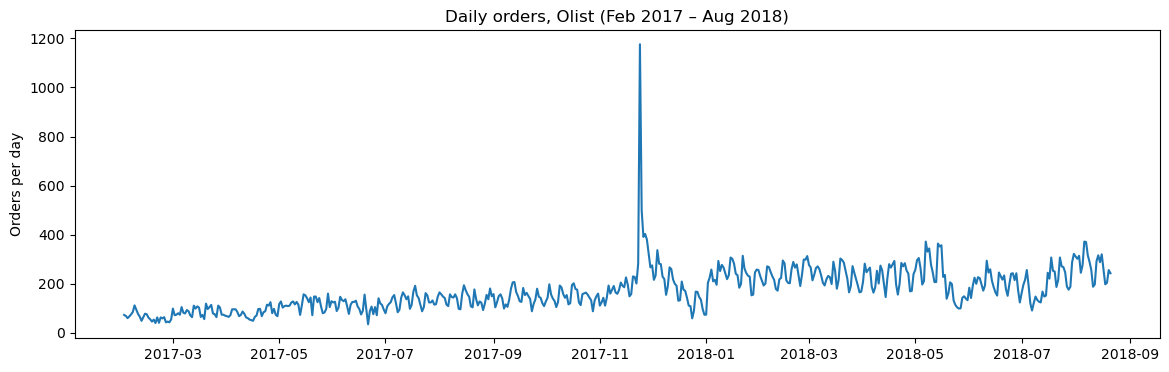

In [14]:
plt.figure(figsize=(14, 4))
plt.plot(df["date"], df["txn_volume"])
plt.title("Daily orders, Olist (Feb 2017 – Aug 2018)")
plt.ylabel("Orders per day")
plt.show()

## 2. Seasonal detector (same day-of-month)

In [15]:
query = open("sql/seasonal_detector.sql").read()
results = duckdb.sql(query).df()   # DuckDB reads the `df` DataFrame directly

print(results["status"].value_counts())
results[results["status"].isin(["WARNING", "CRITICAL"])]

status
NORMAL                342
NOT_ENOUGH_HISTORY    124
WARNING                57
CRITICAL               44
Name: count, dtype: int64


,date,day_of_month,txn_volume,baseline_mean,baseline_std,n_history,z_score,status
124,2017-06-05,5,147,89.000,17.832555,4,3.252478,CRITICAL
125,2017-06-06,6,134,98.750,10.657548,4,3.307515,CRITICAL
132,2017-06-13,13,126,80.500,21.702534,4,2.096529,WARNING
146,2017-06-27,27,141,79.250,27.909079,4,2.212542,WARNING
152,2017-07-03,3,118,79.600,16.652327,5,2.305984,WARNING
...,...,...,...,...,...,...,...,...
532,2018-07-18,18,307,222.250,38.625491,8,2.194147,WARNING
545,2018-07-31,31,322,152.125,50.898884,8,3.337499,CRITICAL
548,2018-08-03,3,314,228.250,36.244211,8,2.365895,WARNING
551,2018-08-06,6,372,222.875,52.572229,8,2.836574,WARNING


## 3. Why so many alerts?

In [16]:
weekday_avg = df.groupby(df["date"].dt.day_name())["txn_volume"].mean().round()
weekday_avg.reindex(["Monday", "Tuesday", "Wednesday", "Thursday",
                     "Friday", "Saturday", "Sunday"])

date
Monday       197.0
Tuesday      194.0
Wednesday    188.0
Thursday     178.0
Friday       171.0
Saturday     132.0
Sunday       145.0
Name: txn_volume, dtype: float64

## 4. Weekday detector (same weekday, last 8 weeks)

In [17]:
weekday_results = duckdb.sql(open("sql/weekday_detector.sql").read()).df()

print(weekday_results["status"].value_counts())
weekday_results[weekday_results["status"] == "CRITICAL"]

status
NORMAL                456
WARNING                54
CRITICAL               29
NOT_ENOUGH_HISTORY     28
Name: count, dtype: int64


,date,weekday,txn_volume,baseline_mean,baseline_std,n_history,z_score,status
94,2017-05-06,Saturday,109,70.750,9.145647,8,4.182318,CRITICAL
95,2017-05-07,Sunday,111,65.875,11.556538,8,3.904716,CRITICAL
109,2017-05-21,Sunday,148,78.750,22.901965,8,3.023758,CRITICAL
140,2017-06-21,Wednesday,35,127.000,12.795088,8,-7.190259,CRITICAL
145,2017-06-26,Monday,72,141.875,16.948978,8,-4.122667,CRITICAL
164,2017-07-15,Saturday,98,79.500,5.580579,8,3.315068,CRITICAL
167,2017-07-18,Tuesday,192,126.875,21.616379,8,3.012762,CRITICAL
178,2017-07-29,Saturday,115,83.375,7.963084,8,3.971451,CRITICAL
218,2017-09-07,Thursday,99,142.875,12.563411,8,-3.492284,CRITICAL
263,2017-10-22,Sunday,158,124.875,5.767830,8,5.743062,CRITICAL


## 5. Comparing the two detectors

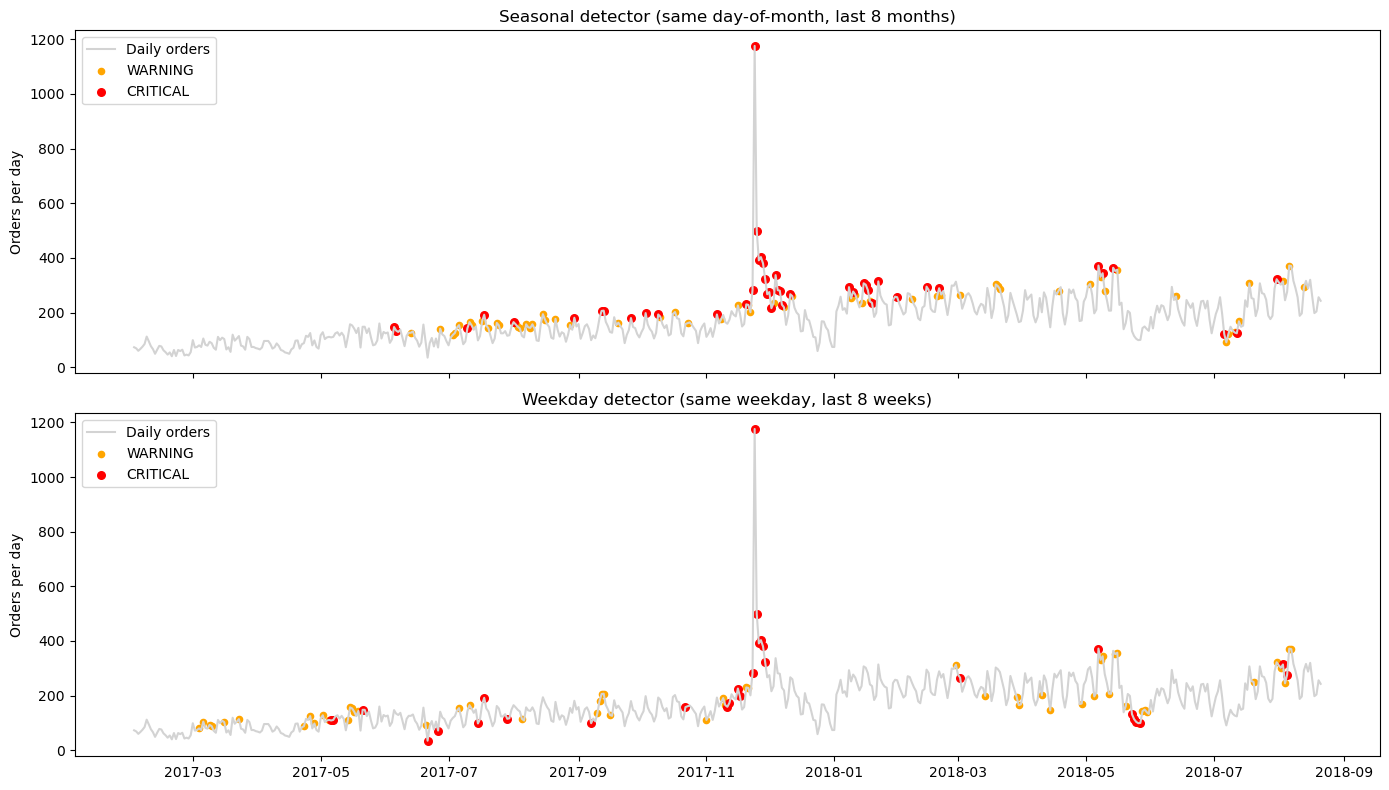

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for ax, data, title in [
    (axes[0], results, "Seasonal detector (same day-of-month, last 8 months)"),
    (axes[1], weekday_results, "Weekday detector (same weekday, last 8 weeks)"),
]:
    ax.plot(data["date"], data["txn_volume"], color="lightgray", label="Daily orders")

    warning = data[data["status"] == "WARNING"]
    critical = data[data["status"] == "CRITICAL"]
    ax.scatter(warning["date"], warning["txn_volume"], color="orange", s=20, label="WARNING")
    ax.scatter(critical["date"], critical["txn_volume"], color="red", s=30, label="CRITICAL")

    ax.set_title(title)
    ax.set_ylabel("Orders per day")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("images/detector_comparison.png", dpi=120)
plt.show()

## 6. Summary

In [19]:
comparison = pd.DataFrame({
    "Seasonal (day-of-month)": results["status"].value_counts(),
    "Weekday (last 8 weeks)": weekday_results["status"].value_counts(),
}).fillna(0).astype(int)
comparison

,Seasonal (day-of-month),Weekday (last 8 weeks)
status,,
CRITICAL,44,29
NORMAL,342,456
NOT_ENOUGH_HISTORY,124,28
WARNING,57,54
